# World Series 2026. What Tampa Bay changed in Game 4

Games 1 through 3 were losses. Game 4 was a 4 to 3 win in twelve innings that kept Tampa Bay alive. This notebook compares that win against the three losses using Statcast pitch level data.

The conclusion the data supports is not the obvious one. Tampa Bay did not hit the ball harder in the win, and its pitching did not prevent runs better than in the Game 1 loss. The win rests on two things. The offense scored four instead of two, and the extra runs came in the situations that decide games. The pitching, for its part, missed enough bats to hold the loudest contact of the series to three runs, with the damage confined to isolated home runs.

A note on method. The win is one game and the losses are three, so any grouped comparison is weighted toward the variance of a single game. The by game tables are the honest reference, and the grouped tables are read for direction only.

## Setup

Install pybaseball, import the libraries, and silence the version warnings so the output stays readable. The warnings are harmless.

In [1]:
!pip install -q pybaseball

import warnings
warnings.simplefilter("ignore", category=FutureWarning)
warnings.simplefilter("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pybaseball import statcast

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

## Load the series

Pull every pitch from October 23 to October 27, which covers Games 1 through 4. Game 5 is left out because it had not been played when this data was pulled. To add it later, extend end_dt and the game map.

Each pitch is labeled with its game, its batting and fielding team, and the Tampa Bay result. Batting and fielding team are derived from the half inning, so the labels stay correct whether Tampa Bay was home or away.

In [2]:
raw = statcast(start_dt="2026-10-23", end_dt="2026-10-27")

game_map = {
    "2026-10-23": "Game 1",
    "2026-10-24": "Game 2",
    "2026-10-26": "Game 3",
    "2026-10-27": "Game 4",
}
result_map = {"Game 1": "Loss", "Game 2": "Loss", "Game 3": "Loss", "Game 4": "Win"}

df = raw.copy()
df["game_date"] = pd.to_datetime(df["game_date"]).dt.strftime("%Y-%m-%d")
df["game"] = df["game_date"].map(game_map)
df = df[df["game"].notna()].copy()
df["tb_result"] = df["game"].map(result_map)

df["batting_team"] = np.where(df["inning_topbot"] == "Top", df["away_team"], df["home_team"])
df["fielding_team"] = np.where(df["inning_topbot"] == "Top", df["home_team"], df["away_team"])
df["tb_batting"] = df["batting_team"] == "TB"
df["tb_pitching"] = df["fielding_team"] == "TB"

df[["game", "tb_result"]].value_counts().sort_index()

This is a large query, it may take a moment to complete


100%|██████████| 5/5 [00:01<00:00,  3.46it/s]


,,count
game,tb_result,
Game 1,Loss,264
Game 2,Loss,341
Game 3,Loss,294
Game 4,Win,367


## 1. Pitch economy

The earlier idea that the win came from longer at bats or cheaper outs does not survive the data, so it is dropped. Economy is measured two clean ways that do not depend on reconstructing outs from play results, which undercounts. Pitches per batter faced, and pitches per inning.

Two reading notes. Pitches per inning uses the half innings actually thrown. Games 1 and 2 show eight innings rather than nine, because Tampa Bay was the visitor and Milwaukee, already leading, did not bat the bottom of the ninth, so Tampa Bay pitched only eight half innings. The count assumes each half inning was completed, which holds for every game here but would overcount a half inning cut short by a walk off. The one metric that separates the win from the losses is the whiff rate. If pitches per batter and per inning are similar across wins and losses, economy was not the difference and bat missing was.

In [3]:
swing_desc = {
    "swinging_strike", "swinging_strike_blocked", "foul", "foul_tip",
    "hit_into_play", "foul_bunt", "missed_bunt",
}
whiff_desc = {"swinging_strike", "swinging_strike_blocked", "foul_tip", "missed_bunt"}

def economy(frame):
    pitches = len(frame)
    bf = int(frame["events"].notna().sum())
    swings = int(frame["description"].isin(swing_desc).sum())
    whiffs = int(frame["description"].isin(whiff_desc).sum())
    strikes = int((frame["type"] != "B").sum())
    innings = frame.drop_duplicates(["inning", "inning_topbot"]).shape[0]
    return pd.Series({
        "pitches": pitches,
        "batters_faced": bf,
        "innings": innings,
        "pitches_per_batter": round(pitches / bf, 2) if bf else np.nan,
        "pitches_per_inning": round(pitches / innings, 1) if innings else np.nan,
        "strike_pct": round(100 * strikes / pitches, 1) if pitches else np.nan,
        "whiff_pct": round(100 * whiffs / swings, 1) if swings else np.nan,
    })

print("Tampa Bay pitching, by game")
display(df[df["tb_pitching"]].groupby("game").apply(economy))

print("Tampa Bay batting, by game (innings and per inning omitted, not meaningful on offense)")
cols = ["pitches", "batters_faced", "pitches_per_batter", "strike_pct", "whiff_pct"]
display(df[df["tb_batting"]].groupby("game").apply(economy)[cols])

Tampa Bay pitching, by game


,pitches,batters_faced,innings,pitches_per_batter,pitches_per_inning,strike_pct,whiff_pct
game,,,,,,,
Game 1,130.0,35.0,8.0,3.71,16.2,63.8,18.0
Game 2,184.0,41.0,8.0,4.49,23.0,61.4,20.2
Game 3,175.0,46.0,9.0,3.80,19.4,61.7,20.5
Game 4,205.0,48.0,12.0,4.27,17.1,62.4,26.0


Tampa Bay batting, by game (innings and per inning omitted, not meaningful on offense)


,pitches,batters_faced,pitches_per_batter,strike_pct,whiff_pct
game,,,,,
Game 1,134.0,34.0,3.94,70.9,21.4
Game 2,157.0,37.0,4.24,66.9,25.0
Game 3,119.0,30.0,3.97,69.7,12.5
Game 4,162.0,43.0,3.77,69.1,23.8


## 2. Contact quality

For every ball put in play, compare the losses against the win on exit velocity, hard hit rate, and expected outcome.

Be precise about what moved. Exit velocity and hard hit rate, which measure how hard the ball was struck, were flat or slightly lower in the win. Expected batting average and expected wOBA were slightly higher, driven by launch angle and placement rather than force. So the raw quality of contact did not improve, even though the expected outcomes ticked up. With one win against three losses, read the grouped view for direction and the by game view as the reference.

The uncomfortable result is on the pitching side. By expected value, Tampa Bay allowed its loudest contact of the series in the win. Section 5 examines it.

In [4]:
def contact(frame):
    bip = frame[frame["type"] == "X"]
    ev = bip["launch_speed"].dropna()
    la = bip["launch_angle"].dropna()
    return pd.Series({
        "balls_in_play": len(bip),
        "avg_exit_velo": round(ev.mean(), 1) if len(ev) else np.nan,
        "hard_hit_pct": round(100 * (ev >= 95).mean(), 1) if len(ev) else np.nan,
        "avg_launch_angle": round(la.mean(), 1) if len(la) else np.nan,
        "xba": round(bip["estimated_ba_using_speedangle"].mean(), 3),
        "xwoba": round(bip["estimated_woba_using_speedangle"].mean(), 3),
    })

print("Tampa Bay batting, losses versus win (direction only, 1 win vs 3 losses)")
display(df[df["tb_batting"]].groupby("tb_result").apply(contact).reindex(["Loss", "Win"]))

print("Tampa Bay batting, by game")
display(df[df["tb_batting"]].groupby("game").apply(contact))

print("Contact allowed by Tampa Bay pitching, by game")
display(df[df["tb_pitching"]].groupby("game").apply(contact))

Tampa Bay batting, losses versus win (direction only, 1 win vs 3 losses)


,balls_in_play,avg_exit_velo,hard_hit_pct,avg_launch_angle,xba,xwoba
tb_result,,,,,,
Loss,69.0,83.1,29.0,7.9,0.282,0.291
Win,32.0,83.0,28.1,5.7,0.327,0.303


Tampa Bay batting, by game


,balls_in_play,avg_exit_velo,hard_hit_pct,avg_launch_angle,xba,xwoba
game,,,,,,
Game 1,22.0,85.9,36.4,8.8,0.300,0.309
Game 2,24.0,78.1,20.8,-2.2,0.258,0.264
Game 3,23.0,85.5,30.4,17.4,0.288,0.299
Game 4,32.0,83.0,28.1,5.7,0.327,0.303


Contact allowed by Tampa Bay pitching, by game


,balls_in_play,avg_exit_velo,hard_hit_pct,avg_launch_angle,xba,xwoba
game,,,,,,
Game 1,26.0,85.5,34.6,8.3,0.324,0.343
Game 2,30.0,93.0,53.3,6.8,0.340,0.376
Game 3,34.0,87.4,38.2,17.0,0.306,0.333
Game 4,32.0,93.8,62.5,20.5,0.376,0.441


## 3. Timing and runners in scoring position

This is the clearest evidence in the notebook. The losses scored early then went quiet, and failed with runners on. This section places runs on the inning timeline and measures performance with a runner on second or third.

The runs driven with runners in scoring position can exceed the hit count, because a sacrifice fly, a bases loaded walk, or an error scores a run without being a hit. The final table breaks those non hit runs out so the Game 1 line can be read correctly.

In [5]:
scoring = df[df["events"].notna()].copy()
scoring["runs_on_pa"] = (scoring["post_bat_score"] - scoring["bat_score"]).clip(lower=0)
tb_runs = scoring[scoring["tb_batting"]]

print("Tampa Bay runs by inning")
display(tb_runs.pivot_table(index="inning", columns="game", values="runs_on_pa", aggfunc="sum", fill_value=0))

risp = tb_runs[tb_runs["on_2b"].notna() | tb_runs["on_3b"].notna()].copy()
hit_events = {"single", "double", "triple", "home_run"}
ab_exclude = {"walk", "intent_walk", "hit_by_pitch", "sac_fly", "sac_bunt", "catcher_interf"}

def risp_profile(frame):
    ab = frame[~frame["events"].isin(ab_exclude)]
    hits = int(frame["events"].isin(hit_events).sum())
    return pd.Series({
        "risp_plate_appearances": len(frame),
        "risp_hits": hits,
        "risp_batting_avg": round(hits / len(ab), 3) if len(ab) else np.nan,
        "runs_driven_with_risp": int(frame["runs_on_pa"].sum()),
    })

print("Tampa Bay with runners in scoring position")
display(risp.groupby("game").apply(risp_profile))

print("Runs driven with runners in scoring position that were not hits")
non_hit_rbi = risp[(risp["runs_on_pa"] > 0) & (~risp["events"].isin(hit_events))]
display(non_hit_rbi.groupby(["game", "events"]).size().rename("count"))

Tampa Bay runs by inning


game,Game 1,Game 2,Game 3,Game 4
inning,,,,
1,0,4,0,0
2,0,0,0,1
3,0,0,0,0
4,1,0,0,1
5,0,0,0,0
6,0,0,0,0
7,0,0,0,0
8,0,0,0,0
9,1,0,1,0


Tampa Bay with runners in scoring position


,risp_plate_appearances,risp_hits,risp_batting_avg,runs_driven_with_risp
game,,,,
Game 1,8.0,0.0,0.000,2.0
Game 2,14.0,3.0,0.214,2.0
Game 3,2.0,1.0,0.500,1.0
Game 4,7.0,3.0,0.429,3.0


Runs driven with runners in scoring position that were not hits


,,count
game,events,
Game 1,field_out,2
Game 4,fielders_choice,1


## 4. The decisive inning, in win probability

The win was not a gradual tilt. It was a comeback in the bottom of the twelfth. Statcast stores the change in win probability on every pitch. Summed across Game 4 from Tampa Bay's side, it shows a game that stayed near even, dropped sharply when Cooper Pratt homered in the top of the twelfth, then recovered on the rally that followed. The path is reconstructed from per pitch changes, so read it as close rather than exact.

The chart is marked at the two turning points. The table lists the ten pitches that moved Tampa Bay's win probability the most, which also surfaces the two Milwaukee home runs, Pratt in the twelfth and David Hamilton in the fifth, that did the damage.

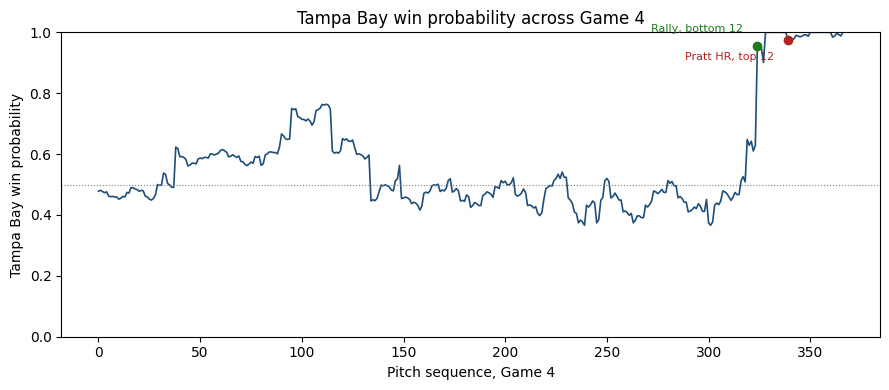

The ten pitches that moved Tampa Bay's win probability the most


,inning,inning_topbot,batting_team,events,des,tb_we_delta
339,12,Top,MIL,home_run,Cooper Pratt homers (1) on a fly ball to left ...,-0.344
324,12,Bot,TB,single,Liam Hicks singles on a ground ball to left fi...,0.327
328,12,Bot,TB,single,Jonny DeLuca singles on a ground ball to cente...,0.219
134,5,Top,MIL,home_run,David Hamilton homers (2) on a fly ball to rig...,-0.151
319,12,Bot,TB,field_error,Junior Caminero reaches on a throwing error by...,0.139
115,4,Top,MIL,double,Cooper Pratt doubles (3) on a line drive to le...,-0.138
38,2,Bot,TB,double,Chandler Simpson doubles (2) on a line drive t...,0.132
333,12,Bot,TB,single,Chandler Simpson singles on a line drive to ce...,0.132
149,6,Bot,TB,double_play,"Jonathan Aranda lines into a double play, seco...",-0.109
95,4,Bot,TB,fielders_choice,"Brewers challenged (tag play), call on the fie...",0.1


In [6]:
g4 = df[df["game"] == "Game 4"].copy()
g4 = g4.sort_values(["inning", "inning_topbot", "at_bat_number", "pitch_number"]).reset_index(drop=True)

tb_home_g4 = bool((g4["home_team"] == "TB").iloc[0])
sign = 1 if tb_home_g4 else -1
g4["tb_we_delta"] = sign * g4["delta_home_win_exp"].fillna(0)
g4["tb_we"] = (0.5 + g4["tb_we_delta"].cumsum()).clip(0, 1)

drop_idx = int(g4["tb_we_delta"].idxmin())   # Pratt home run
rally_idx = int(g4["tb_we_delta"].idxmax())  # largest Tampa Bay swing back

plt.figure(figsize=(9, 4))
plt.plot(range(len(g4)), g4["tb_we"], color="#1f4e79", linewidth=1.2)
plt.axhline(0.5, color="grey", linewidth=0.8, linestyle=":")
plt.scatter([rally_idx], [g4.loc[rally_idx, "tb_we"]], color="#1f7a1f", zorder=5)
plt.annotate("Rally, bottom 12", (rally_idx, g4.loc[rally_idx, "tb_we"]),
             textcoords="offset points", xytext=(-10, 10), fontsize=8, color="#1f7a1f", ha="right")
plt.scatter([drop_idx], [g4.loc[drop_idx, "tb_we"]], color="#b22222", zorder=5)
plt.annotate("Pratt HR, top 12", (drop_idx, g4.loc[drop_idx, "tb_we"]),
             textcoords="offset points", xytext=(-10, -14), fontsize=8, color="#b22222", ha="right")
plt.ylim(0, 1)
plt.xlabel("Pitch sequence, Game 4")
plt.ylabel("Tampa Bay win probability")
plt.title("Tampa Bay win probability across Game 4")
plt.tight_layout()
plt.show()

print("The ten pitches that moved Tampa Bay's win probability the most")
top = g4.reindex(g4["tb_we_delta"].abs().sort_values(ascending=False).index).head(10)
display(top[["inning", "inning_topbot", "batting_team", "events", "des", "tb_we_delta"]])

## 5. Contact allowed versus runs allowed

By expected value Tampa Bay allowed its loudest contact of the series in the win, yet gave up only three runs in twelve innings. The reason is bat missing, not contact suppression. A high whiff rate reduced balls in play, which reduced baserunners.

Stranding alone does not explain it. The best loss, Game 1, allowed the same three runs on the same twelve baserunners and stranded at the same rate, so a plain strand rate does not separate the win from a loss. What separates the win is the shape of the damage. The table splits runs allowed into home run damage and everything else. Read the non home run line. In the win Tampa Bay allowed the most home runs of the series but the fewest non home run runs, which means the damage arrived in isolated swings rather than a cluster of hits. Game 3, the blowout, is the opposite, where the runs came clustered.

In [7]:
onbase = {"single", "double", "triple", "home_run", "walk", "intent_walk",
          "hit_by_pitch", "field_error", "catcher_interf"}
mil_bat = scoring[scoring["tb_pitching"]].copy()

def allowed(frame):
    reached = int(frame["events"].isin(onbase).sum())
    runs = int(frame["runs_on_pa"].sum())
    hr = int((frame["events"] == "home_run").sum())
    hr_runs = int(frame.loc[frame["events"] == "home_run", "runs_on_pa"].sum())
    non_hr_reached = reached - hr
    non_hr_runs = runs - hr_runs
    return pd.Series({
        "batters_reached": reached,
        "runs_allowed": runs,
        "strand_rate_pct": round(100 * (reached - runs) / reached, 1) if reached else np.nan,
        "home_runs_allowed": hr,
        "non_hr_reached": non_hr_reached,
        "non_hr_runs": non_hr_runs,
        "non_hr_runs_per_reached": round(non_hr_runs / non_hr_reached, 2) if non_hr_reached else np.nan,
    })

print("Tampa Bay pitching, damage split by home run and non home run")
display(mil_bat.groupby("game").apply(allowed))

print("For reference, expected contact allowed on balls in play, by game")
display(df[df["tb_pitching"]].groupby("game").apply(contact)[["balls_in_play", "xwoba"]])

Tampa Bay pitching, damage split by home run and non home run


,batters_reached,runs_allowed,strand_rate_pct,home_runs_allowed,non_hr_reached,non_hr_runs,non_hr_runs_per_reached
game,,,,,,,
Game 1,12.0,3.0,75.0,0.0,12.0,3.0,0.25
Game 2,17.0,5.0,70.6,1.0,16.0,4.0,0.25
Game 3,20.0,10.0,50.0,0.0,20.0,10.0,0.50
Game 4,12.0,3.0,75.0,2.0,10.0,1.0,0.10


For reference, expected contact allowed on balls in play, by game


,balls_in_play,xwoba
game,,
Game 1,26.0,0.343
Game 2,30.0,0.376
Game 3,34.0,0.333
Game 4,32.0,0.441


## 6. Workload and physical effort

Game 4 ran twelve innings, so in raw terms it demanded more than the losses, not less. The question is how the effort was spread. Tampa Bay used the most pitchers and threw the most pitches, but no single arm carried the peak load of Games 2 and 3, where one reliever reached the high eighties.

Through the first nine innings Game 4 cost about 15.6 pitches per inning, the most efficient regulation rate of the series and below the full game rate of every loss. The extra innings cost about 21.7 per inning, which is where fatigue showed and what pushed the full game figure up. The third table lists the arms that pitched the extra innings, which shows whether leverage pitching was still available when the game was decided.

In [8]:
tb_pit = df[df["tb_pitching"]].copy()

pc = tb_pit.groupby(["game", "pitcher", "player_name"]).size().rename("pitches").reset_index()
workload = pc.groupby("game").agg(
    pitchers_used=("pitcher", "nunique"),
    total_pitches=("pitches", "sum"),
    max_pitches_one_arm=("pitches", "max"),
    median_pitches_per_arm=("pitches", "median"),
)
print("Tampa Bay pitching workload by game")
display(workload)

g4p = tb_pit[tb_pit["game"] == "Game 4"].copy()
g4p["phase"] = np.where(g4p["inning"] <= 9, "Innings 1 to 9", "Extra innings")
phase = g4p.groupby("phase").agg(pitches=("phase", "size"), innings=("inning", "nunique"))
phase["pitches_per_inning"] = round(phase["pitches"] / phase["innings"], 1)
print("Game 4, regular versus extra innings")
display(phase)

print("Game 4 arms that pitched the extra innings")
extra = g4p[g4p["inning"] >= 10]
display(extra.groupby("player_name").size().rename("pitches_in_extras").sort_values(ascending=False))

Tampa Bay pitching workload by game


,pitchers_used,total_pitches,max_pitches_one_arm,median_pitches_per_arm
game,,,,
Game 1,5,130,73,12.0
Game 2,6,184,89,22.5
Game 3,6,175,87,16.5
Game 4,7,205,74,24.0


Game 4, regular versus extra innings


,pitches,innings,pitches_per_inning
phase,,,
Extra innings,65,3,21.7
Innings 1 to 9,140,9,15.6


Game 4 arms that pitched the extra innings


,pitches_in_extras
player_name,
"Seymour, Ian",32
"Wells, Tyler",24
"Booser, Cam",9


## 7. Opportunism, measured by leverage

This isolates the clutch claim. A plate appearance is high leverage when it is late and close, meaning the seventh inning or later with the score within two runs. Everything else is low leverage, including the innings after Game 3 was out of reach. If opportunism was the difference, the high leverage line should separate the win from the losses while the low leverage line stays close.

Two notes. Game 3 had zero high leverage plate appearances, because once it became a blowout every late at bat came with the margin above two runs, so it appears as an empty row in the by game table. And each high leverage bucket holds roughly twenty plate appearances, which is small. This section supports the runners in scoring position result in Section 3, which points the same way and is the cleaner read, rather than standing on its own.

In [9]:
bat = df[df["tb_batting"] & df["events"].notna()].copy()
bat["margin"] = bat["bat_score"] - bat["fld_score"]
bat["leverage"] = np.where(
    (bat["inning"] >= 7) & (bat["margin"].abs() <= 2),
    "High, late and close",
    "Low, other",
)
bat["runs_on_pa"] = (bat["post_bat_score"] - bat["bat_score"]).clip(lower=0)

def clutch(frame):
    ab = frame[~frame["events"].isin(ab_exclude)]
    hits = int(frame["events"].isin(hit_events).sum())
    denom = frame["woba_denom"].sum()
    woba = frame["woba_value"].sum() / denom if denom else np.nan
    return pd.Series({
        "plate_appearances": len(frame),
        "batting_avg": round(hits / len(ab), 3) if len(ab) else np.nan,
        "woba": round(woba, 3),
        "runs": int(frame["runs_on_pa"].sum()),
    })

print("Tampa Bay batting by leverage and result")
display(bat.groupby(["leverage", "tb_result"]).apply(clutch).sort_index())

print("High leverage only, by game (Game 3 had no high leverage plate appearances)")
hi = bat[bat["leverage"] == "High, late and close"].groupby("game").apply(clutch)
display(hi.reindex(["Game 1", "Game 2", "Game 3", "Game 4"]))

Tampa Bay batting by leverage and result


plate_appearances  batting_avg   woba  runs
leverage             tb_result                                             
High, late and close Loss                    23.0        0.143  0.193   1.0
                     Win                     22.0        0.238  0.277   2.0
Low, other           Loss                    78.0        0.194  0.255   6.0
                     Win                     21.0        0.190  0.231   2.0

High leverage only, by game (Game 3 had no high leverage plate appearances)


,plate_appearances,batting_avg,woba,runs
game,,,,
Game 1,12.0,0.182,0.208,1.0
Game 2,11.0,0.100,0.177,0.0
Game 3,NaN,NaN,NaN,NaN
Game 4,22.0,0.238,0.277,2.0


## 8. The whole comparison on one chart

This radar places Tampa Bay's losses against the Game 4 win on six axes, each scaled across the four games so the position shows where a value sits within the series. Every axis is oriented so that outward means more favorable to Tampa Bay. Two of them are inverted to keep that rule. Contact suppressed is the inverse of expected wOBA allowed, and non home run run suppression is the inverse of non home run runs per baserunner, so on both, outward means less damage allowed.

The shape is the conclusion. The win polygon expands where the win was earned, bat missing, high leverage hitting, runners in scoring position, and non home run suppression. It sits on top of the losses on exit velocity, because Tampa Bay did not hit the ball harder. And it collapses toward the center on contact suppressed, because it allowed the loudest contact of the series. Tampa Bay won by missing bats and hitting in the right moments, not by cleaner contact, and in spite of what it allowed.

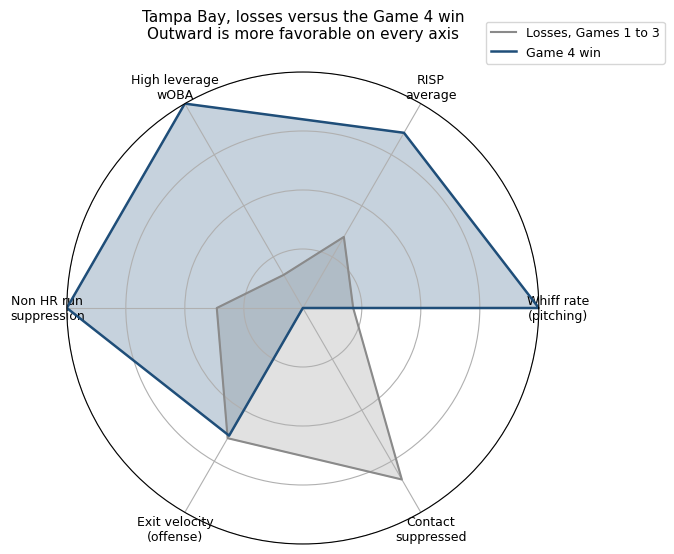

Raw values behind the chart


,Losses (G1-3),Game 4 win
whiff,19.742,26.042
risp_ba,0.174,0.429
hilev_woba,0.193,0.277
exit_velo,83.081,82.984
xwoba_allowed,0.350,0.441
nonhr_rate,0.354,0.100


In [11]:
def radar_metrics(frame):
    b = frame[frame["tb_batting"]]
    p = frame[frame["tb_pitching"]]

    sw = p["description"].isin(swing_desc).sum()
    wh = p["description"].isin(whiff_desc).sum()
    whiff = 100 * wh / sw if sw else np.nan

    br = b[b["events"].notna()]
    rb = br[br["on_2b"].notna() | br["on_3b"].notna()]
    ab = rb[~rb["events"].isin(ab_exclude)]
    risp_ba = rb["events"].isin(hit_events).sum() / len(ab) if len(ab) else np.nan

    m = br["bat_score"] - br["fld_score"]
    hi = br[(br["inning"] >= 7) & (m.abs() <= 2)]
    den = hi["woba_denom"].sum()
    hilev_woba = hi["woba_value"].sum() / den if den else np.nan

    ev = b[b["type"] == "X"]["launch_speed"].dropna()
    exit_velo = ev.mean() if len(ev) else np.nan

    pbip = p[p["type"] == "X"]
    xwoba_allowed = pbip["estimated_woba_using_speedangle"].mean()

    ps = p[p["events"].notna()].copy()
    ps["r"] = (ps["post_bat_score"] - ps["bat_score"]).clip(lower=0)
    reached = ps["events"].isin(onbase).sum()
    runs = ps["r"].sum()
    hr = (ps["events"] == "home_run").sum()
    hr_runs = ps.loc[ps["events"] == "home_run", "r"].sum()
    nonhr_rate = (runs - hr_runs) / (reached - hr) if (reached - hr) else np.nan

    return {"whiff": whiff, "risp_ba": risp_ba, "hilev_woba": hilev_woba,
            "exit_velo": exit_velo, "xwoba_allowed": xwoba_allowed, "nonhr_rate": nonhr_rate}

per_game = {g: radar_metrics(df[df["game"] == g]) for g in ["Game 1", "Game 2", "Game 3", "Game 4"]}
loss = radar_metrics(df[df["tb_result"] == "Loss"])
win = radar_metrics(df[df["tb_result"] == "Win"])

# (key, label, higher_is_better). Inverted axes are set False so outward stays "better".
axes = [
    ("whiff",         "Whiff rate\n(pitching)",      True),
    ("risp_ba",       "RISP\naverage",               True),
    ("hilev_woba",    "High leverage\nwOBA",         True),
    ("nonhr_rate",    "Non HR run\nsuppression",     False),
    ("exit_velo",     "Exit velocity\n(offense)",    True),
    ("xwoba_allowed", "Contact\nsuppressed",         False),
]

def norm(key, val, higher):
    vals = [per_game[g][key] for g in per_game if not np.isnan(per_game[g][key])]
    lo, hi = min(vals), max(vals)
    if hi == lo:
        return 0.5
    x = (val - lo) / (hi - lo)
    return float(np.clip(x if higher else 1 - x, 0, 1))

labels = [lab for _, lab, _ in axes]
loss_vals = [norm(k, loss[k], h) for k, _, h in axes]
win_vals = [norm(k, win[k], h) for k, _, h in axes]

ang = np.linspace(0, 2 * np.pi, len(axes), endpoint=False).tolist()
ang += ang[:1]
loss_vals += loss_vals[:1]
win_vals += win_vals[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.plot(ang, loss_vals, color="#8a8a8a", linewidth=1.5, label="Losses, Games 1 to 3")
ax.fill(ang, loss_vals, color="#8a8a8a", alpha=0.25)
ax.plot(ang, win_vals, color="#1f4e79", linewidth=1.8, label="Game 4 win")
ax.fill(ang, win_vals, color="#1f4e79", alpha=0.25)
ax.set_xticks(ang[:-1])
ax.set_xticklabels(labels, fontsize=9)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels([])
ax.set_ylim(0, 1)
ax.set_title("Tampa Bay, losses versus the Game 4 win\nOutward is more favorable on every axis", fontsize=11, pad=24)
ax.legend(loc="upper right", bbox_to_anchor=(1.28, 1.12), fontsize=9)
plt.tight_layout()
plt.show()

print("Raw values behind the chart")
display(pd.DataFrame({"Losses (G1-3)": loss, "Game 4 win": win}).round(3))